<a href="https://colab.research.google.com/github/SanskritiVij/tp53-mutation-analysis/blob/main/TP53_mutation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

mut = pd.read_csv("/data_mutations.txt", sep="\t", comment="#", low_memory=False)
print(mut.shape)
print(mut[["Hugo_Symbol", "Variant_Classification", "HGVSp_Short", "Tumor_Sample_Barcode"]].head())

(126252, 111)
  Hugo_Symbol Variant_Classification   HGVSp_Short Tumor_Sample_Barcode
0       GATA3        Frame_Shift_Ins  p.P408Afs*99      TCGA-3C-AAAU-01
1      MALAT1                    RNA      p.*2558*      TCGA-3C-AAAU-01
2       CD248      Missense_Mutation       p.E678K      TCGA-3C-AAAU-01
3     NAALAD2                 Intron       p.*426*      TCGA-3C-AAAU-01
4       CNPY2                  5'UTR        p.*98*      TCGA-3C-AAAU-01


In [ ]:
mut["Hugo_Symbol"].nunique()

18987

In [ ]:
tp53 = mut[mut["Hugo_Symbol"] == "TP53"].copy()
print("TP53 mutations:", tp53.shape[0])
print("Samples with TP53 mutation:", tp53["Tumor_Sample_Barcode"].nunique())
print("Total samples:", mut["Tumor_Sample_Barcode"].nunique())
print(tp53["Variant_Classification"].value_counts())

TP53 mutations: 356
Samples with TP53 mutation: 348
Total samples: 1009
Variant_Classification
Missense_Mutation    216
Frame_Shift_Del       47
Nonsense_Mutation     46
Splice_Site           24
Frame_Shift_Ins       14
In_Frame_Del           5
Silent                 2
Splice_Region          1
3'UTR                  1
Name: count, dtype: int64


In [ ]:
pct = 100 * tp53["Tumor_Sample_Barcode"].nunique() / mut["Tumor_Sample_Barcode"].nunique()
print(round(pct, 1), "% of samples have a TP53 mutation")

34.5 % of samples have a TP53 mutation


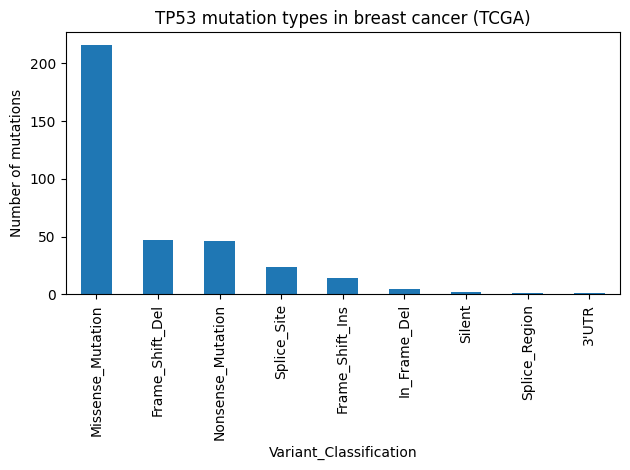

In [ ]:
import matplotlib.pyplot as plt

tp53["Variant_Classification"].value_counts().plot(kind="bar")
plt.title("TP53 mutation types in breast cancer (TCGA)")
plt.ylabel("Number of mutations")
plt.tight_layout()
plt.savefig("tp53_mutation_types.png", dpi=200)
plt.show()

In [ ]:
print(tp53["HGVSp_Short"].value_counts().head(10))

HGVSp_Short
p.R175H          21
p.R273H          13
p.R196*           8
p.Y220C           7
p.R342*           7
p.R213*           7
p.H179R           6
p.H193R           6
p.R273C           5
p.X225_splice     5
Name: count, dtype: int64


Each row in the mutation file is one mutation found in one tumor sample. The file has 126,252 mutations across 18,987 genes and 1,009 samples. Hugo_Symbol is the gene name. Variant_Classification is the type of change. HGVSp_Short is the change at the protein level, so p.R175H means the arginine at position 175 became histidine. Tumor_Sample_Barcode is the ID of the tumor sample.
TP53 has 356 mutations in 348 of the 1,009 samples, which is 34.5%. A few samples carry more than one TP53 mutation.
Missense mutations are the most common type, with 216 of 356 (about 61%). A missense change swaps one amino acid for another, so the protein is still made but may not work. Most of the rest are frameshift, nonsense, and splice site changes, which usually break the protein.
The top hotspot is R175H (21 samples), followed by R273H (13) and Y220C (7). R273 is changed in two ways (R273H and R273C), 18 samples in total. These positions fall inside the DNA-binding domain of p53, so a change there likely stops the protein from binding DNA and switching on its target genes.


In [8]:
from google.colab import files
files.download("tp53_mutation_types.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!pip install lifelines -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 13.5 MB/s eta 0:00:00


In [10]:
clin = pd.read_csv("/data_clinical_patient.txt", sep="\t", comment="#")
print(clin[["PATIENT_ID", "OS_STATUS", "OS_MONTHS"]].head())
print(clin.shape)

     PATIENT_ID OS_STATUS   OS_MONTHS
0  TCGA-3C-AAAU  0:LIVING  133.050597
1  TCGA-3C-AALI  0:LIVING  131.669790
2  TCGA-3C-AALJ  0:LIVING   48.459743
3  TCGA-3C-AALK  0:LIVING   47.604958
4  TCGA-4H-AAAK  0:LIVING   11.440971
(1084, 38)


In [11]:
mut["PATIENT_ID"] = mut["Tumor_Sample_Barcode"].str[:12]
tp53_patients = set(tp53[tp53["Variant_Classification"] != "Silent"]["Tumor_Sample_Barcode"].str[:12])

clin["OS_MONTHS"] = pd.to_numeric(clin["OS_MONTHS"], errors="coerce")
clin = clin.dropna(subset=["OS_STATUS", "OS_MONTHS"]).copy()
clin = clin[clin["PATIENT_ID"].isin(mut["PATIENT_ID"])].copy()
clin["event"] = clin["OS_STATUS"].str.startswith("1").astype(int)
clin["TP53_mutant"] = clin["PATIENT_ID"].isin(tp53_patients)

print(clin["TP53_mutant"].value_counts())
print("Deaths:", clin["event"].sum())

TP53_mutant
False    661
True     348
Name: count, dtype: int64
Deaths: 136


log-rank p-value: 0.48332180023134474


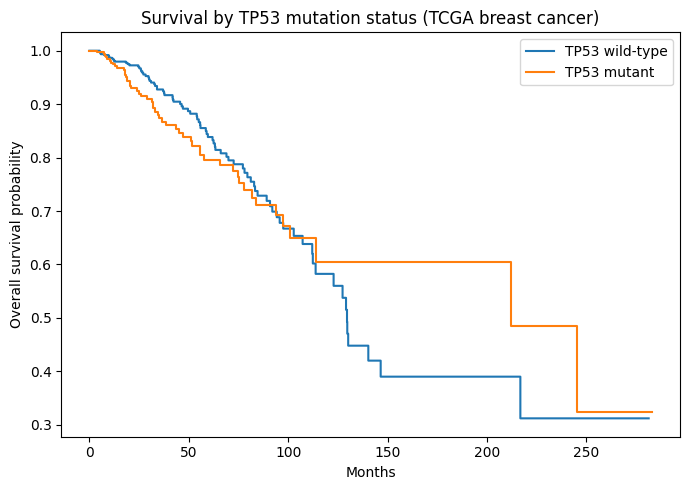

In [12]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(7, 5))

for flag, grp in clin.groupby("TP53_mutant"):
    name = "TP53 mutant" if flag else "TP53 wild-type"
    kmf.fit(grp["OS_MONTHS"], grp["event"], label=name)
    kmf.plot_survival_function(ax=ax, ci_show=False)

m = clin[clin["TP53_mutant"]]
w = clin[~clin["TP53_mutant"]]
res = logrank_test(m["OS_MONTHS"], w["OS_MONTHS"], m["event"], w["event"])
print("log-rank p-value:", res.p_value)

ax.set_xlabel("Months")
ax.set_ylabel("Overall survival probability")
ax.set_title("Survival by TP53 mutation status (TCGA breast cancer)")
plt.tight_layout()
plt.savefig("tp53_survival.png", dpi=200)
plt.show()

I compared overall survival between patients with a TP53 mutation (348) and without one (661) using Kaplan-Meier curves and a log-rank test. There were 136 deaths in total. The log-rank p-value was 0.48, so there was no significant difference in survival between the groups. The mutant curve sits slightly below the wild-type curve for the first 80 months or so, and the two cross at around 100 months. After about 120 months the curves separate again, but few patients are followed that long, so that part rests on a handful of events. This analysis does not adjust for subtype, stage, or age.